# Les réseaux de neurones apprennent-ils d'abord les basses fréquences ?

On entraîne des réseaux à reproduire la fonction de l'expérience 3.1 de Rahaman et al. (*On the Spectral Bias of Neural Networks*, 2019) : une somme de 10 sinus de fréquences 5, 10, …, 50, de même amplitude, avec des phases aléatoires. On regarde **dans quel ordre** les réseaux retrouvent chaque fréquence au fil des epochs.

On compare quatre cas, avec le même nombre de poids et presque la même architecture (3 couches cachées) :

1. un **MLP** classique (ReLU), entraîné $N_1$ epochs ;
2. **le même MLP** entraîné plus longtemps, $N_2 > N_1$ epochs ;
3. un MLP dont l'entrée $x$ est remplacée par des **Fourier features** $\big(\cos(2\pi b_j x), \sin(2\pi b_j x)\big)$, entraîné $N_1$ epochs ;
4. un **SIREN**, c'est-à-dire un MLP dont l'activation est $\sin$ au lieu de ReLU, entraîné $N_1$ epochs.

Ce qu'on s'attend à voir : le MLP apprend d'abord les variations lentes (basses fréquences) et n'attrape les variations rapides que très tard ; les deux autres réseaux, qui manipulent directement des sinus, devraient retrouver les hautes fréquences beaucoup plus vite.

La partie 2 refait la même comparaison sur une image.

In [ ]:
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

FREQS = list(range(5, 55, 5))                                          # k_i = 5, 10, ..., 50 (cycles sur [0, 1])
PHASES = np.random.default_rng(0).uniform(0, 2 * np.pi, len(FREQS))    # phases φ_i tirées dans U(0, 2π)
N1 = 1_000                                                             # nombre d'epochs "court"
N2 = 10_000                                                            # nombre d'epochs "long" (MLP seulement)
LRS = {"MLP": 1e-3, "Fourier features": 1e-3, "SIREN": 1e-4}           # pas d'Adam (SIREN : valeur du papier original)

COLORS = ["#257de0", "#f47230", "#00b894", "#f2a600"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "font.size": 9, "legend.frameon": False})

## La fonction à apprendre

Comme dans la section 3.1 de Rahaman et al., avec toutes les amplitudes égales à 1 :

$$y(x) = \sum_{i=1}^{10} \sin(2\pi k_i x + \varphi_i), \qquad k_i \in \{5, 10, \dots, 50\}, \quad \varphi_i \sim \mathcal U(0, 2\pi), \quad x \in [0, 1).$$

On entraîne sur 200 points régulièrement espacés, comme dans le papier, et on évalue sur 1 024 points, ce qui teste aussi ce que le réseau fait entre les points vus. Chaque epoch est un passage sur les 200 points, en un seul batch. Différences avec le papier, pour que le notebook tourne en environ deux minutes sur CPU : réseau plus petit (3 × 64 au lieu de 6 × 256) et 10 000 epochs au lieu de 80 000.

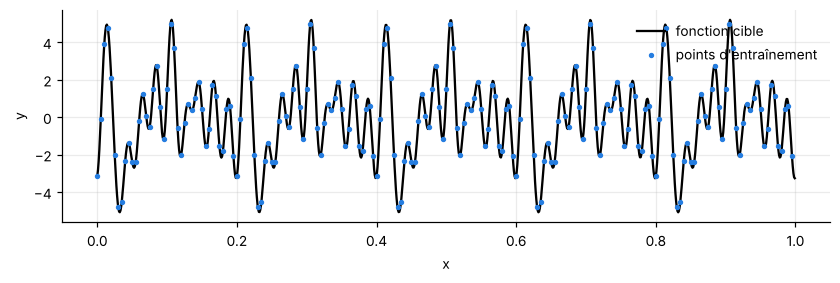

In [ ]:
def target(x):
    return sum(torch.sin(2 * math.pi * k * x + phi) for k, phi in zip(FREQS, PHASES))

x_train = torch.arange(200)[:, None] / 200
y_train = target(x_train)
x_eval = torch.arange(1024)[:, None] / 1024
y_eval = target(x_eval)

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.plot(x_eval, y_eval, color="black", lw=1.5, label="fonction cible")
ax.plot(x_train, y_train, "o", ms=2.5, color=COLORS[0], label="points d'entraînement")
ax.set(xlabel="x", ylabel="y")
ax.legend(loc="upper right")
plt.show()

## Les trois réseaux

Tous ont 3 couches cachées et environ 8 500 poids.

- **MLP** : $x \to$ 64 → 64 → 64 → sortie, activation ReLU.
- **Fourier features** : on remplace $x$ par 16 paires $\big(\cos(2\pi b_j x), \sin(2\pi b_j x)\big)$, avec des fréquences $b_j$ tirées au hasard une fois pour toutes (loi normale d'écart-type 5) et non apprises. L'entrée passe donc de 1 à 32 valeurs, ce qui ajoute des poids dans la première couche : pour compenser, on réduit un peu la largeur des couches cachées.
- **SIREN** : même architecture que le MLP, mais avec l'activation $\sin(30\,\cdot)$. Comme dans le papier de Sitzmann et al., on adapte l'initialisation des poids pour que les sinus ne saturent pas, et on ramène $x$ dans $[-1, 1]$.

Le paramètre `n_in` (nombre d'entrées) vaut 1 ici ; il servira pour l'image, où il vaut 2.

In [ ]:
def mlp(n_in, width):
    return nn.Sequential(nn.Linear(n_in, width), nn.ReLU(),
                         nn.Linear(width, width), nn.ReLU(),
                         nn.Linear(width, width), nn.ReLU(),
                         nn.Linear(width, 1))


class FourierFeaturesMLP(nn.Module):
    def __init__(self, n_freqs, sigma, width, n_in=1):
        super().__init__()
        self.register_buffer("b", torch.randn(n_in, n_freqs) * sigma)   # fréquences fixes, non apprises
        self.net = mlp(2 * n_freqs, width)

    def forward(self, x):
        z = 2 * math.pi * x @ self.b
        return self.net(torch.cat([torch.cos(z), torch.sin(z)], dim=-1))


class Sine(nn.Module):
    def __init__(self, w0):
        super().__init__()
        self.w0 = w0

    def forward(self, x):
        return torch.sin(self.w0 * x)


class Siren(nn.Module):
    def __init__(self, width, w0=30.0, n_in=1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, width), Sine(w0),
                                 nn.Linear(width, width), Sine(w0),
                                 nn.Linear(width, width), Sine(w0),
                                 nn.Linear(width, 1))
        with torch.no_grad():                                           # initialisation du papier SIREN
            self.net[0].weight.uniform_(-1 / n_in, 1 / n_in)
            for layer in self.net[2::2]:
                bound = math.sqrt(6 / width) / w0
                layer.weight.uniform_(-bound, bound)

    def forward(self, x):
        return self.net(2 * x - 1)                                      # x ramené dans [-1, 1]


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def same_size_width(make_with_width, n_target):
    """Largeur pour laquelle le réseau a le nombre de poids le plus proche de n_target."""
    return min(range(8, 300), key=lambda w: abs(n_params(make_with_width(w)) - n_target))


ff_width = same_size_width(lambda w: FourierFeaturesMLP(16, 5.0, w), n_params(mlp(1, 64)))

MAKERS = {
    "MLP":              lambda: mlp(1, 64),
    "Fourier features": lambda: FourierFeaturesMLP(16, 5.0, ff_width),
    "SIREN":            lambda: Siren(64),
}
for name, make in MAKERS.items():
    print(f"{name:17s} {n_params(make()):5d} poids")

MLP                8513 poids
Fourier features   8551 poids
SIREN              8513 poids


## Mesurer les fréquences apprises

À chaque epoch, on calcule la transformée de Fourier de la sortie du réseau sur les 1 024 points d'évaluation, et on la compare à celle de la cible, fréquence par fréquence :

$$\text{amplitude retrouvée}(k) = \frac{|\text{FFT}(\text{sortie du réseau})[k]|}{|\text{FFT}(\text{cible})[k]|}.$$

Elle vaut 0 quand le réseau ignore la fréquence $k$ et 1 quand il la reproduit avec la bonne amplitude.

La fonction `train` sert pour toute la suite, en 1D comme sur l'image. Elle entraîne le réseau sur `(x, y)`, et toutes les `every` epochs elle l'évalue sur une grille et applique une fonction de mesure (ici `recovered`). Elle garde aussi la prédiction complète à quelques epochs choisies (`snapshot_at`), pour les figures.

In [ ]:
F_target = torch.fft.rfft(y_eval[:, 0])

def recovered(pred):
    """Amplitude retrouvée pour chaque fréquence de la cible."""
    F_pred = torch.fft.rfft(pred[:, 0])
    return (F_pred[FREQS].abs() / F_target[FREQS].abs()).numpy()


def train(model, x, y, grid, epochs, lr, measure, snapshot_at=(), every=1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, snapshots = {}, {}
    for epoch in range(epochs + 1):
        if epoch % every == 0 or epoch in snapshot_at:
            with torch.no_grad():
                pred = model(grid)
            history[epoch] = measure(pred)
            if epoch in snapshot_at:
                snapshots[epoch] = pred
        if epoch == epochs:
            break
        loss = ((model(x) - y) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return history, snapshots


SNAPS = [10, 30, 100, N1, N2]
runs = {}
for name, make in MAKERS.items():
    torch.manual_seed(1)                        # même graine pour tous
    epochs = N2 if name == "MLP" else N1        # le MLP long contient aussi le MLP court (son état à l'epoch N1)
    runs[name] = train(make(), x_train, y_train, x_eval, epochs, LRS[name], recovered, snapshot_at=SNAPS)

## Résultats

Le « MLP entraîné $N_1$ epochs » est simplement l'état du MLP long à l'epoch $N_1$ : même initialisation, mêmes données, donc exactement le même réseau que si on l'avait entraîné séparément.

### 1. Les fréquences retrouvées au fil des epochs

C'est la figure principale, l'équivalent de la figure 1 du papier : chaque ligne est une fréquence, chaque colonne une epoch, et la couleur indique l'amplitude retrouvée (blanc : pas encore apprise ; bleu foncé : apprise). L'axe des epochs est logarithmique pour voir à la fois le début et la fin de l'entraînement. Sur le panneau du MLP, la ligne pointillée marque $N_1$.

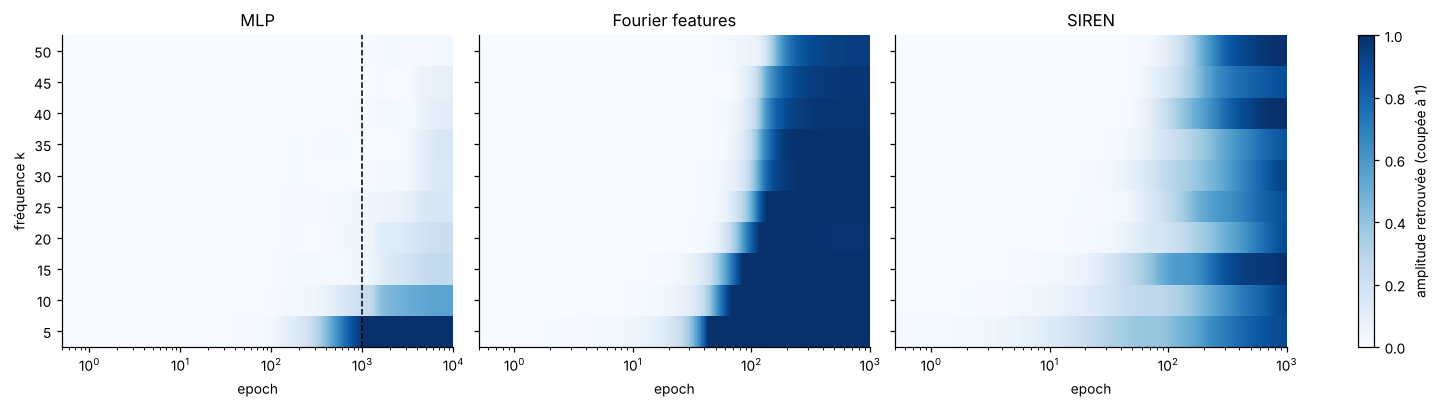

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, layout="constrained")
for ax, name in zip(axes, MAKERS):
    history = runs[name][0]
    epochs = np.array(list(history))[1:]                  # on saute l'epoch 0 (axe logarithmique)
    values = np.array(list(history.values()))[1:]
    im = ax.pcolormesh(epochs, FREQS, values.T, cmap="Blues", vmin=0, vmax=1, shading="nearest")
    if name == "MLP":
        ax.axvline(N1, color="black", ls="--", lw=1)
    ax.set(xscale="log", xlabel="epoch", title=name, yticks=FREQS)
    ax.grid(False)
axes[0].set_ylabel("fréquence k")
fig.colorbar(im, ax=axes, label="amplitude retrouvée (coupée à 1)")
plt.show()

### 2. Ce que les réseaux ont appris, à différents moments

Chaque ligne est un réseau, chaque colonne un moment de l'entraînement. La cible est en gris.

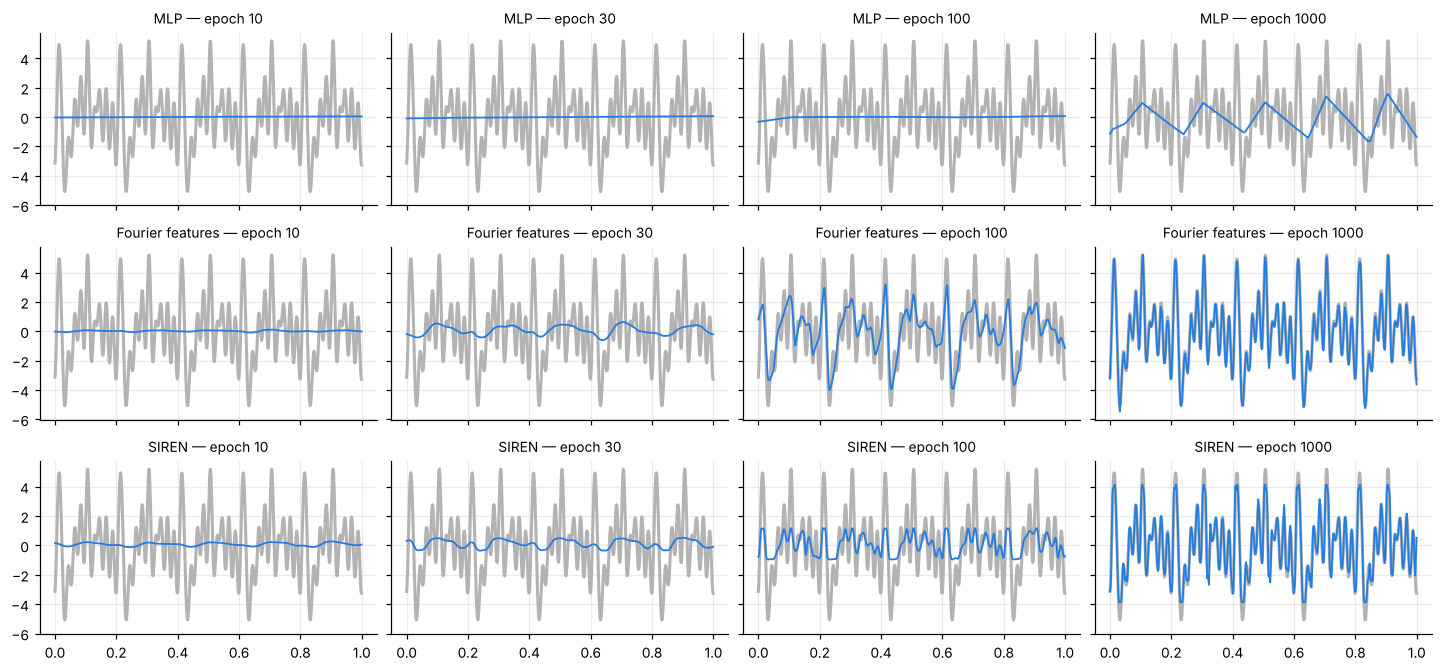

In [ ]:
cols = [10, 30, 100, N1]
fig, axes = plt.subplots(3, len(cols), figsize=(13, 6), sharex=True, sharey=True, layout="constrained")
for i, name in enumerate(MAKERS):
    for j, ep in enumerate(cols):
        ax = axes[i, j]
        ax.plot(x_eval, y_eval, color="0.7", lw=2)
        ax.plot(x_eval, runs[name][1][ep], color=COLORS[0], lw=1.2)
        ax.set_title(f"{name} — epoch {ep}", fontsize=9)
plt.show()

### 3. Bilan : fonction apprise et spectre en fin d'entraînement

À gauche, la prédiction et la cible. À droite, l'amplitude de chaque fréquence dans la prédiction : chaque sinus de la cible a une amplitude de 1 (points noirs). Le titre indique aussi la part de l'énergie que le réseau met sur des fréquences absentes de la cible.

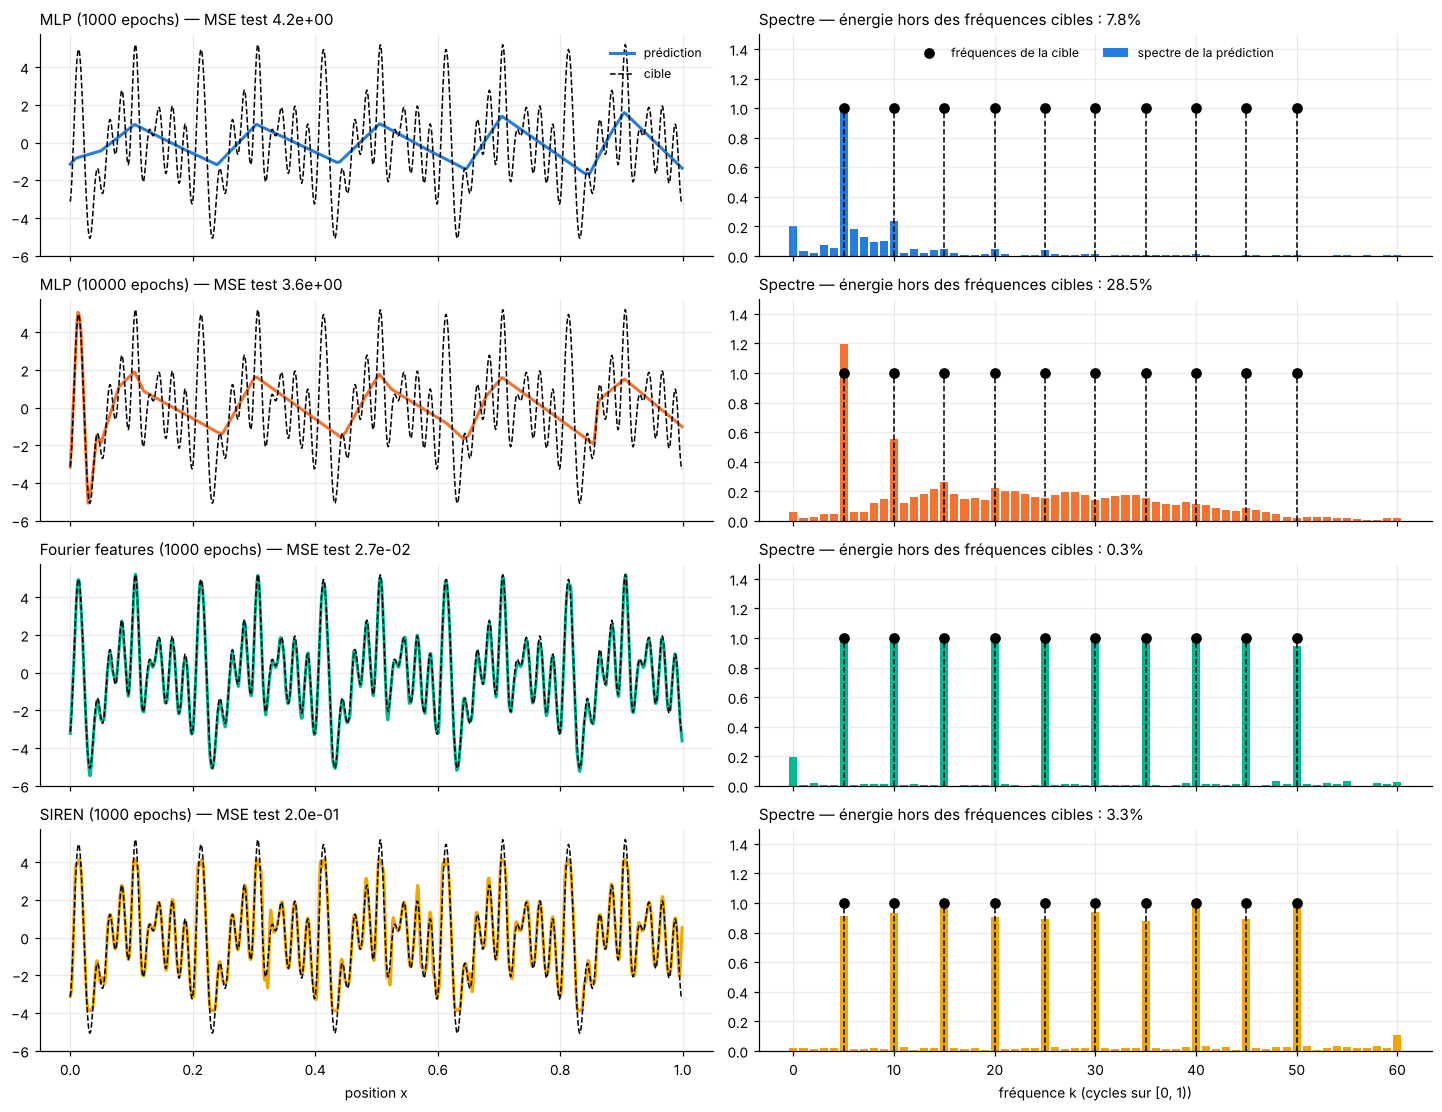

In [ ]:
def amplitudes(signal):
    """Amplitude du sinus de fréquence k, pour k = 0, 1, 2, ... (signal sur une grille régulière de [0, 1))."""
    return 2 * np.abs(np.fft.rfft(signal)) / len(signal)


panels = {
    f"MLP ({N1} epochs)":              runs["MLP"][1][N1],
    f"MLP ({N2} epochs)":              runs["MLP"][1][N2],
    f"Fourier features ({N1} epochs)": runs["Fourier features"][1][N1],
    f"SIREN ({N1} epochs)":            runs["SIREN"][1][N1],
}
x, y = x_eval[:, 0].numpy(), y_eval[:, 0].numpy()
k = np.arange(max(FREQS) + 11)                                  # fréquences affichées : 0 à 60
off_target = [j for j in range(1, len(x) // 2 + 1) if j not in FREQS]

fig, axes = plt.subplots(len(panels), 2, figsize=(13, 10), sharex="col", sharey="col", layout="constrained")
for i, (title, pred) in enumerate(panels.items()):
    pred = pred[:, 0].numpy()
    amp = amplitudes(pred)
    mse = ((pred - y) ** 2).mean()
    off = (amp[off_target] ** 2).sum() / (amp[1:] ** 2).sum()    # part de l'énergie hors des fréquences cibles

    axes[i, 0].plot(x, pred, color=COLORS[i], lw=2, label="prédiction")
    axes[i, 0].plot(x, y, "--", color="black", lw=1, label="cible")
    axes[i, 0].set_title(f"{title} — MSE test {mse:.1e}", loc="left", fontsize=10)

    axes[i, 1].bar(k, amp[k], color=COLORS[i], label="spectre de la prédiction")
    axes[i, 1].vlines(FREQS, 0, 1, color="black", ls="--", lw=1)
    axes[i, 1].plot(FREQS, np.ones(len(FREQS)), "o", color="black", label="fréquences de la cible")
    axes[i, 1].set_title(f"Spectre — énergie hors des fréquences cibles : {off:.1%}", loc="left", fontsize=10)

axes[0, 0].legend(loc="upper right", fontsize=8)
axes[0, 1].set_ylim(0, 1.5)
axes[0, 1].legend(loc="upper center", ncol=2, fontsize=8)
axes[-1, 0].set_xlabel("position x")
axes[-1, 1].set_xlabel("fréquence k (cycles sur [0, 1))")
plt.show()

## Conclusion (1D)

- **Le MLP apprend clairement les basses fréquences d'abord.** À $N_1 = 1\,000$ epochs, il n'a appris que $k = 5$ : sa prédiction est une ligne brisée qui suit la plus lente des oscillations. Après 10 fois plus d'epochs, $k = 10$ n'est retrouvée qu'à moitié et les autres fréquences à environ 20 %. En plus, le MLP met beaucoup d'énergie hors des fréquences de la cible (28 % à $N_2$) : ce sont ses cassures ReLU. L'erreur de test reste énorme (environ 4).
- **Les Fourier features apprennent tout en 300 à 350 epochs, mais toujours dans l'ordre.** La carte montre un front en diagonale très net, de $k = 5$ vers 40 epochs à $k = 50$ vers 350. Le biais spectral n'est pas supprimé, il est accéléré. L'erreur de test finale est de $3 \cdot 10^{-2}$, avec seulement 0.3 % d'énergie hors cible.
- **SIREN n'a pas d'ordre net :** toutes les fréquences montent en même temps et atteignent environ 90 % de leur amplitude à $N_1$ (erreur de test de $0.2$, encore en train de baisser avec le pas de $10^{-4}$).
- **À nombre de poids égal,** changer l'entrée ou l'activation compte beaucoup plus qu'entraîner 10 fois plus longtemps.

Ces résultats viennent d'une seule graine : pour le rapport, il faut les répéter sur plusieurs tirages, comme Rahaman et al. qui moyennent sur 10 tirages de phases.